# Eje 10a — Market Data II: IV, estrategias y arbitrajes

Derivados Financieros · QUANt UCEMA

Cierra el bloque de datos: a partir de una cadena (US), calculamos IV por strike,
armamos una estrategia simple y chequeamos **paridad put–call** (base de arbitraje).

Requiere red (`yfinance` / `Codigo.data.market_data`). Si falla el fetch, el notebook
cae a un panel sintético para no romper la clase.

**Plan**
1. Traer spot + cadena
2. IV por strike (BS)
3. Smile ATM
4. Estrategia (call spread) con mids
5. Paridad put–call residual
6. Resumen

## 1) Setup

In [1]:
import math
import sys
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

print("OK")

OK


In [2]:
from Codigo.pricing import opcion_europea_bs, precio_estrategia
from Codigo.analytics.vol_implicita import impvolfunc_bs

## 2) Spot + cadena (con fallback sintético)

In [3]:
ticker = "AAPL"
panel = None
spot = None
try:
    from Codigo.data import market_data as md
    spot = float(md.get_spot(ticker))
    chain = md.get_options_chain(ticker)
    # chain suele traer calls/puts; normalizamos a DataFrame simple
    if isinstance(chain, dict):
        calls = chain.get("calls") or chain.get("Calls")
        puts = chain.get("puts") or chain.get("Puts")
        if calls is not None and puts is not None:
            c = calls.copy(); c["tipo"] = "C"
            p = puts.copy(); p["tipo"] = "P"
            panel = pd.concat([c, p], ignore_index=True)
    elif isinstance(chain, pd.DataFrame):
        panel = chain.copy()
    print("Fuente: market_data | spot=", spot, "| filas=", 0 if panel is None else len(panel))
except Exception as e:
    print("Fetch falló, uso panel sintético:", type(e).__name__, str(e)[:100])

if panel is None or spot is None or len(panel) < 5:
    spot = 100.0
    T = 45 / 365
    r, div = 0.05, 0.0
    rows = []
    for K in [85, 90, 95, 100, 105, 110, 115]:
        sig = 0.22 + 0.004 * abs(K - 100) / 5
        for tipo in ("C", "P"):
            mid = opcion_europea_bs(tipo, spot, K, T, r, sig, div)
            rows.append({"tipo": tipo, "strike": K, "mid": mid, "T": T, "impliedVolatility": sig})
    panel = pd.DataFrame(rows)
    print("Panel sintético | spot=", spot)

# columnas flexibles
cols = {c.lower(): c for c in panel.columns}
def col(*names):
    for n in names:
        if n in panel.columns: return n
        if n.lower() in cols: return cols[n.lower()]
    return None

c_strike = col("strike", "Strike", "K")
c_tipo = col("tipo", "type", "optionType")
c_mid = col("mid", "lastPrice", "last", "precio")
c_T = col("T", "ttm", "expiryT")
print(panel.head())

Fuente: market_data | spot= 341.07000732421875 | filas= 2786
  symbol  expiration  type       contractSymbol  strike currency  lastPrice  \
0   AAPL  2026-09-28  call  AAPL260928C00250000   250.0      USD      89.85   
1   AAPL  2026-09-28  call  AAPL260928C00265000   265.0      USD      72.52   
2   AAPL  2026-09-28  call  AAPL260928C00270000   270.0      USD      65.74   
3   AAPL  2026-09-28  call  AAPL260928C00280000   280.0      USD      58.20   
4   AAPL  2026-09-28  call  AAPL260928C00290000   290.0      USD      46.83   

   change  percentChange  volume  openInterest  bid  ask contractSize  \
0     0.0            0.0     1.0             0  0.0  0.0      REGULAR   
1     0.0            0.0     4.0             5  0.0  0.0      REGULAR   
2     0.0            0.0     2.0             2  0.0  0.0      REGULAR   
3     0.0            0.0     2.0             3  0.0  0.0      REGULAR   
4     0.0            0.0     2.0            12  0.0  0.0      REGULAR   

        lastTradeDate  im

## 3) IV por strike (calls cerca de ATM)

In [4]:
r, div = 0.05, 0.0
work = panel.copy()
if c_tipo and work[c_tipo].dtype == object:
    work[c_tipo] = work[c_tipo].astype(str).str.upper().str[0]
calls = work[work[c_tipo] == "C"].copy() if c_tipo else work.copy()
# T: si no hay columna, asumir 45d
if c_T is None:
    calls["T"] = 45 / 365
    c_T = "T"
# mid
if c_mid is None:
    raise RuntimeError("No hay columna de precio mid/last en el panel")

atm = calls.iloc[(calls[c_strike] - spot).abs().argsort()[:8]].copy()
ivs = []
for _, row in atm.iterrows():
    try:
        iv = impvolfunc_bs("C", spot, float(row[c_strike]), float(row[c_T]), r, float(row[c_mid]), div)
    except Exception:
        iv = np.nan
    ivs.append(iv)
atm["IV_bs"] = ivs
atm[[c_strike, c_mid, "IV_bs"]].dropna().round(6)

,strike,lastPrice,IV_bs
2082,340.0,50.74,1.039157
1413,340.0,26.20,0.517757
535,340.0,7.82,0.128510
2705,340.0,76.80,1.602427
910,340.0,14.65,0.273669
2481,340.0,62.67,1.295438
1544,340.0,28.32,0.562593


## 4) Smile

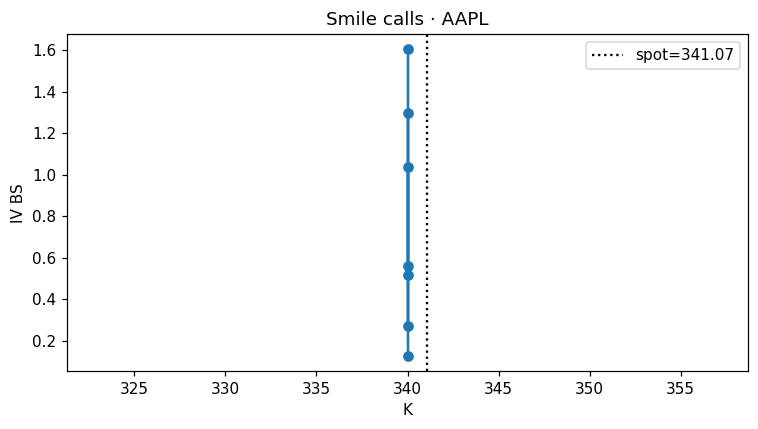

In [5]:
plot_df = atm.dropna(subset=["IV_bs"]).sort_values(c_strike)
fig, ax = plt.subplots(figsize=(7, 4), dpi=110)
ax.plot(plot_df[c_strike], plot_df["IV_bs"], "o-")
ax.axvline(spot, color="k", ls=":", label=f"spot={spot:.2f}")
ax.set_xlabel("K"); ax.set_ylabel("IV BS"); ax.legend()
ax.set_title(f"Smile calls · {ticker}")
plt.tight_layout(); plt.show()

## 5) Estrategia — call spread con mids de mercado

In [6]:
# Elegimos dos strikes call OTM crecientes
cs = plot_df.sort_values(c_strike)
if len(cs) >= 2:
    k1, k2 = float(cs.iloc[0][c_strike]), float(cs.iloc[min(2, len(cs)-1)][c_strike])
    m1, m2 = float(cs.iloc[0][c_mid]), float(cs.iloc[min(2, len(cs)-1)][c_mid])
    T_ = float(cs.iloc[0][c_T])
    # long k1 / short k2
    debit = m1 - m2
    print(f"Call spread K={k1}/{k2}  debit mid ≈ {debit:.4f}")
    # valor teórico BS con IV media
    iv_m = float(cs["IV_bs"].mean())
    theo = (
        opcion_europea_bs("C", spot, k1, T_, r, iv_m, div)
        - opcion_europea_bs("C", spot, k2, T_, r, iv_m, div)
    )
    print(f"Theo BS (IV media {iv_m:.2%}) ≈ {theo:.4f}  | mid−theo = {debit-theo:.4f}")
else:
    print("Pocos strikes para armar spread")

Call spread K=340.0/340.0  debit mid ≈ 42.9200
Theo BS (IV media 77.42%) ≈ 0.0000  | mid−theo = 42.9200


## 6) Paridad put–call

$$
C - P = S e^{-qT} - K e^{-rT}
$$

Residual grande ⇒ datos / americanas / dividendos / mid stale (oportunidad o ruido).

      K     C-P    parity  residual
0   5.0  333.59  336.1007   -2.5107
1  10.0  303.08  331.1315  -28.0515
2  15.0  297.87  326.1622  -28.2922
3  20.0  292.67  321.1929  -28.5229
4  25.0  286.16  316.2236  -30.0636
5  30.0  283.61  311.2544  -27.6444
6  35.0  266.31  306.2851  -39.9751
7  40.0  269.33  301.3158  -31.9858
8  45.0  254.56  296.3466  -41.7866
9  50.0  288.84  291.3773   -2.5373

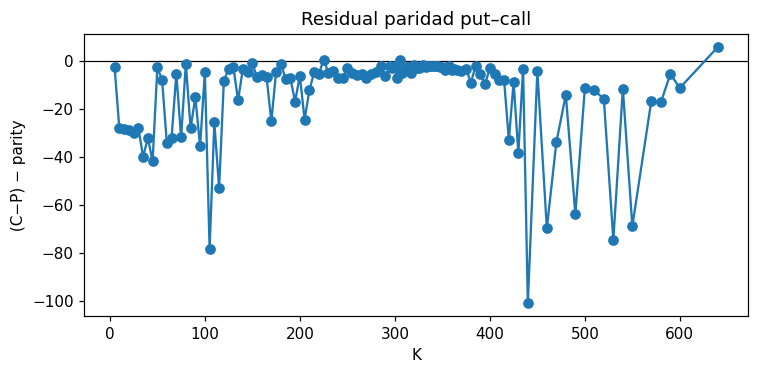

In [7]:
puts = work[work[c_tipo] == "P"].copy() if c_tipo else pd.DataFrame()
rows = []
if len(puts) and c_strike and c_mid:
    for K in sorted(set(calls[c_strike]) & set(puts[c_strike])):
        c_row = calls[calls[c_strike] == K].iloc[0]
        p_row = puts[puts[c_strike] == K].iloc[0]
        T_ = float(c_row[c_T]) if c_T in c_row else 45/365
        lhs = float(c_row[c_mid]) - float(p_row[c_mid])
        rhs = spot * np.exp(-div * T_) - float(K) * np.exp(-r * T_)
        rows.append({"K": float(K), "C-P": lhs, "parity": rhs, "residual": lhs - rhs})
par = pd.DataFrame(rows).sort_values("K")
print(par.round(4).head(10))
if len(par):
    fig, ax = plt.subplots(figsize=(7, 3.5), dpi=110)
    ax.axhline(0, color="k", lw=0.8)
    ax.plot(par["K"], par["residual"], "o-")
    ax.set_xlabel("K"); ax.set_ylabel(" (C−P) − parity ")
    ax.set_title("Residual paridad put–call")
    plt.tight_layout(); plt.show()

## Resumen

- Market Data II conecta cadena → IV → estrategia → chequeo de paridad.
- Residuales de paridad no son “free lunch” automáticos (americanas, fees, stale quotes).
- Para BYMA: mismo flujo con paneles del eje 4c.

**Ejercicio:** repetí el smile con puts y compará IV call vs put ATM.